# A/B-тест: снижают ли SMS-напоминания неявки?

**Контекст.** Каждая неявка — пустой слот врача: клиника теряет выручку, а другой клиент не смог записаться.
С 1 марта 2026 клиника тестирует SMS-напоминание накануне приёма.

**Гипотеза.** Напоминание снижает долю неявок. H0: доля неявок в группах одинакова. H1: отличается
(двусторонний тест — напоминание теоретически может и раздражать).

| | |
| --- | --- |
| **Единица рандомизации** | запись на приём: каждую запись монетка 50/50 отправляет в группу |
| **Участники** | записи хотя бы за день до приёма (при записи в тот же день SMS не отправляют) |
| **Treatment / control** | SMS-напоминание отправлено / не отправлено |
| **Основная метрика** | доля неявок среди неотменённых записей: `неявки / (пришли + не пришли)` |
| **Барьерные метрики** | доля отмен, выручка на запись — не должны ухудшиться |
| **Уровень значимости и мощность** | α = 0.05, 1 − β = 0.8 |
| **Период** | 1 марта — 31 октября 2026, длительность зафиксирована заранее |

**План.** 1) Проверить, что эксперимент проведён корректно (SRM, баланс групп). 2) Разобрать ловушку наивного
сравнения. 3) Оценить эффект с интервалами. 4) Проверить устойчивость: кластерный бутстрап, CUPED, стабильность
во времени. 5) Мощность, A/A-тесты и подглядывание. 6) Сегменты. 7) Барьерные метрики. 8) Деньги и решение.

Данные — представление `metrics.experiment_visits` (см. `dwh/metrics/08_experiment.sql`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import abtest
import db

pd.set_option("display.precision", 4)
FIG_DIR = "figures"

# Цвета: контроль и тест — первые два слота проверенной категориальной палитры; текст — нейтральный.
COLORS = {"control": "#2a78d6", "treatment": "#eb6834"}
LABELS = {"control": "контроль (без SMS)", "treatment": "тест (SMS)"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "font.size": 11,
        "lines.linewidth": 2,
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "savefig.bbox": "tight",
    }
)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


def num(x):
    """Число с пробелом между разрядами: 12 345."""
    return f"{x:,.0f}".replace(",", " ")


def pp(x, digits=2):
    """Процентные пункты: разница двух долей."""
    return f"{100 * x:+.{digits}f} п.п."

In [2]:
visits = db.query("SELECT * FROM metrics.experiment_visits")
visits["visit_date"] = pd.to_datetime(visits["visit_date"])
visits["revenue"] = visits["revenue"].astype(float)

exp = visits[visits["period"] == "experiment"].copy()  # все записи эксперимента, включая отмены
main = exp[exp["is_attended_or_no_show"]].copy()  # база основной метрики: без отмен
pre = visits[(visits["period"] == "pre") & visits["is_attended_or_no_show"]].copy()

start, end = exp["visit_date"].min().date(), exp["visit_date"].max().date()
display(
    Markdown(
        f"Эксперимент: **{start} — {end}**, {(end - start).days + 1} дней. "
        f"Записей в эксперименте: **{num(len(exp))}**, из них неотменённых: **{num(len(main))}**, "
        f"клиентов: **{num(exp['owner_id'].nunique())}**. До эксперимента для A/A-проверок: {num(len(pre))} записей."
    )
)
exp.groupby("ab_group").agg(
    записей=("visit_id", "size"),
    неотменённых=("is_attended_or_no_show", "sum"),
    неявок=("is_no_show", "sum"),
    клиентов=("owner_id", "nunique"),
)

Эксперимент: **2026-03-01 — 2026-10-31**, 245 дней. Записей в эксперименте: **9 667**, из них неотменённых: **9 016**, клиентов: **3 256**. До эксперимента для A/A-проверок: 12 731 записей.

,записей,неотменённых,неявок,клиентов
ab_group,,,,
control,4816,4470,408,2476
treatment,4851,4546,314,2505


## 1. Корректность эксперимента

Прежде чем смотреть на эффект, проверяем, что сравнивать вообще можно. Если сплит сломан, любые цифры дальше —
мусор, и это самая частая причина неверных выводов из A/B-тестов.

**SRM (sample ratio mismatch)** — проверка, что группы получились в задуманной пропорции 50/50. Тест хи-квадрат;
порог p < 0.001 (строже обычного: тревога при SRM дешевле, чем выводы из сломанного теста). Проверяем на всех записях,
включая отменённые: рандомизация происходит в момент записи, до того как человек решил отменить.

In [3]:
counts = exp["ab_group"].value_counts()
srm = abtest.srm_test(int(counts["control"]), int(counts["treatment"]))

weekly = exp.groupby(["week_start", "ab_group"]).size().unstack()
weekly_p = [abtest.srm_test(int(r["control"]), int(r["treatment"])).p_value for _, r in weekly.iterrows()]

display(
    Markdown(
        f"Доля теста: **{pct(srm.share_b, 2)}**, χ² = {srm.chi2:.2f}, p-value = **{srm.p_value:.3f}** → "
        f"{'сплит в порядке' if srm.ok else '**SRM! Результатам верить нельзя**'}. "
        f"По неделям: SRM (p < 0.001) в {sum(p < 0.001 for p in weekly_p)} из {len(weekly_p)} недель."
    )
)

Доля теста: **50.18%**, χ² = 0.13, p-value = **0.722** → сплит в порядке. По неделям: SRM (p < 0.001) в 0 из 36 недель.

**Баланс групп.** Если рандомизация честная, группы похожи по всему, что известно до отправки SMS. Мера —
стандартизованная разница средних (SMD): разница средних в единицах стандартного отклонения, |SMD| < 0.1 — хороший баланс.

In [4]:
features = pd.DataFrame(
    {
        "срок записи, дней": exp["lead_days"],
        "запись на понедельник": exp["is_monday"].astype(float),
        "утренний слот (до 11:00)": exp["is_early_slot"].astype(float),
        "час приёма": exp["visit_hour"],
        "осмотр": (exp["visit_type"] == "checkup").astype(float),
        "вакцинация": (exp["visit_type"] == "vaccination").astype(float),
        "лечение": (exp["visit_type"] == "treatment").astype(float),
        "хирургия": (exp["visit_type"] == "surgery").astype(float),
    }
)
is_b = exp["ab_group"].eq("treatment").to_numpy()
balance = pd.DataFrame(
    {
        "контроль": features[~is_b].mean(),
        "тест": features[is_b].mean(),
        "SMD": [abtest.standardized_mean_difference(features[c][~is_b], features[c][is_b]) for c in features],
    }
).round(3)
display(
    Markdown(
        f"Максимальный |SMD| = **{balance['SMD'].abs().max():.3f}** — группы сбалансированы."
        if balance["SMD"].abs().max() < 0.1
        else "**Есть дисбаланс по признакам — разобраться!**"
    )
)
balance

Максимальный |SMD| = **0.047** — группы сбалансированы.

,контроль,тест,SMD
"срок записи, дней",5.429,5.506,0.016
запись на понедельник,0.163,0.148,-0.041
утренний слот (до 11:00),0.131,0.134,0.011
час приёма,14.605,14.572,-0.011
осмотр,0.383,0.407,0.047
вакцинация,0.224,0.213,-0.028
лечение,0.324,0.313,-0.024
хирургия,0.069,0.068,-0.002


## 2. Ловушка: наивное сравнение

Самый быстрый «анализ» — сравнить все приёмы с SMS и без SMS за период эксперимента. Но SMS никогда не получают
записи в тот же день, и все они оказываются в «без SMS». Такие записи почти не теряются (человек записался час назад),
поэтому «без SMS» выглядит лучше, чем настоящий контроль, и эффект занижается.

Правильно сравнивать только тех, кого разбила монетка: записи хотя бы за день. Это и есть разница между
**«получил SMS»** и **«был назначен в группу»** — анализ по назначению (intention-to-treat) сравнивает группы такими,
какими их сделала рандомизация.

In [5]:
naive = db.query("SELECT * FROM metrics.experiment_naive_comparison")
same_day = db.query("""
    SELECT round(100.0 * avg(is_no_show::int), 2) AS no_show_pct, count(*) AS n
    FROM mart.fact_visits
    WHERE lead_days = 0 AND (is_completed OR is_no_show)
      AND visit_date >= (SELECT start_date FROM metrics.experiment_period)
      AND visit_date <= (SELECT end_date FROM metrics.experiment_period)
""").iloc[0]

rates = main.groupby("ab_group")["is_no_show"].mean()
naive_rates = naive.set_index("naive_group")["no_show_pct"].astype(float) / 100
naive_lift = naive_rates.loc["с SMS"] / naive_rates.drop("с SMS").iloc[0] - 1
correct_lift = rates["treatment"] / rates["control"] - 1

display(
    Markdown(
        f"Записи в тот же день: {int(same_day['n'])} шт., неявок **{same_day['no_show_pct']}%**.\n\n"
        f"| Сравнение | Без SMS | С SMS | Эффект |\n| --- | ---: | ---: | ---: |\n"
        f"| Наивное (все приёмы) | {pct(naive_rates.drop('с SMS').iloc[0], 2)} | {pct(naive_rates.loc['с SMS'], 2)} "
        f"| {pct(naive_lift)} |\n"
        f"| Правильное (участники эксперимента) | {pct(rates['control'], 2)} | {pct(rates['treatment'], 2)} "
        f"| **{pct(correct_lift)}** |\n\n"
        f"Наивное сравнение занижает эффект примерно на {100 * (correct_lift - naive_lift) / correct_lift:.0f}% — "
        f"и бизнес недооценил бы пользу напоминаний."
    )
)

Записи в тот же день: 1548 шт., неявок **6.07%**.

| Сравнение | Без SMS | С SMS | Эффект |
| --- | ---: | ---: | ---: |
| Наивное (все приёмы) | 8.34% | 6.91% | -17.1% |
| Правильное (участники эксперимента) | 9.13% | 6.91% | **-24.3%** |

Наивное сравнение занижает эффект примерно на 30% — и бизнес недооценил бы пользу напоминаний.

## 3. Результат

Z-тест для двух долей. Интервал для абсолютной разницы — обычный (Вальда), для относительной — дельта-методом
на логарифме отношения долей.

In [6]:
g = main.groupby("ab_group")["is_no_show"].agg(["sum", "count"])
res = abtest.two_proportion_ztest(
    int(g.loc["control", "sum"]),
    int(g.loc["control", "count"]),
    int(g.loc["treatment", "sum"]),
    int(g.loc["treatment", "count"]),
)
ci = {k: abtest.wilson_ci(int(g.loc[k, "sum"]), int(g.loc[k, "count"])) for k in ["control", "treatment"]}

display(
    Markdown(
        f"| | Контроль | Тест |\n| --- | ---: | ---: |\n"
        f"| Неотменённых записей | {int(g.loc['control', 'count'])} | {int(g.loc['treatment', 'count'])} |\n"
        f"| Неявок | {int(g.loc['control', 'sum'])} | {int(g.loc['treatment', 'sum'])} |\n"
        f"| Доля неявок [95% ДИ] | {pct(res.p_a, 2)} [{pct(ci['control'][0], 2)}; {pct(ci['control'][1], 2)}] "
        f"| {pct(res.p_b, 2)} [{pct(ci['treatment'][0], 2)}; {pct(ci['treatment'][1], 2)}] |\n\n"
        f"**Абсолютный эффект:** {pp(res.diff)} [95% ДИ {pp(res.diff_ci[0])}; {pp(res.diff_ci[1])}]  \n"
        f"**Относительный эффект:** {pct(res.lift)} [95% ДИ {pct(res.lift_ci[0])}; {pct(res.lift_ci[1])}]  \n"
        f"z = {res.z:.2f}, **p-value = {res.p_value:.1e}** → "
        f"{'эффект статистически значим' if res.significant else 'значимого эффекта нет'}."
    )
)

| | Контроль | Тест |
| --- | ---: | ---: |
| Неотменённых записей | 4470 | 4546 |
| Неявок | 408 | 314 |
| Доля неявок [95% ДИ] | 9.13% [8.32%; 10.01%] | 6.91% [6.21%; 7.68%] |

**Абсолютный эффект:** -2.22 п.п. [95% ДИ -3.34 п.п.; -1.10 п.п.]  
**Относительный эффект:** -24.3% [95% ДИ -34.3%; -12.8%]  
z = -3.88, **p-value = 1.0e-04** → эффект статистически значим.

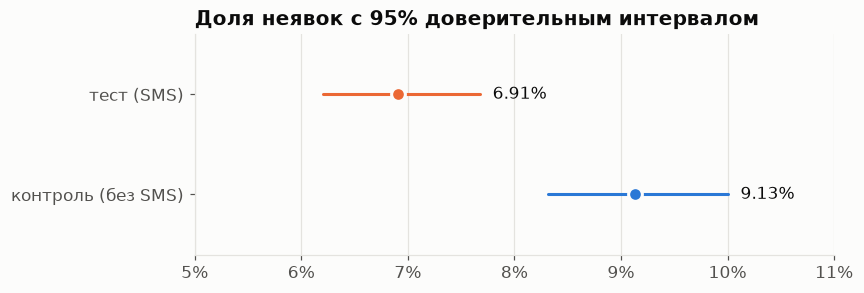

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 2.6))
for i, grp in enumerate(["control", "treatment"]):
    p = rates[grp]
    low, high = ci[grp]
    ax.plot([low, high], [i, i], color=COLORS[grp], linewidth=2, solid_capstyle="round")
    ax.plot(p, i, "o", color=COLORS[grp], markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"{pct(p, 2)}", (high, i), xytext=(8, 0), textcoords="offset points", va="center", color=INK)
ax.set_yticks([0, 1], [LABELS["control"], LABELS["treatment"]])
ax.set_ylim(-0.6, 1.6)
ax.xaxis.set_major_formatter(lambda x, _: f"{100 * x:.0f}%")
ax.set_xlim(0.05, 0.11)
ax.grid(axis="y", visible=False)
ax.set_title("Доля неявок с 95% доверительным интервалом")
fig.savefig(f"{FIG_DIR}/01_no_show_by_group.png")
plt.show()

**Стабильность во времени.** Эффект может держаться на одной удачной неделе или угасать, когда новизна проходит
(novelty effect). Смотрим накопленную долю неявок по дням и сравниваем первую и вторую половину эксперимента.

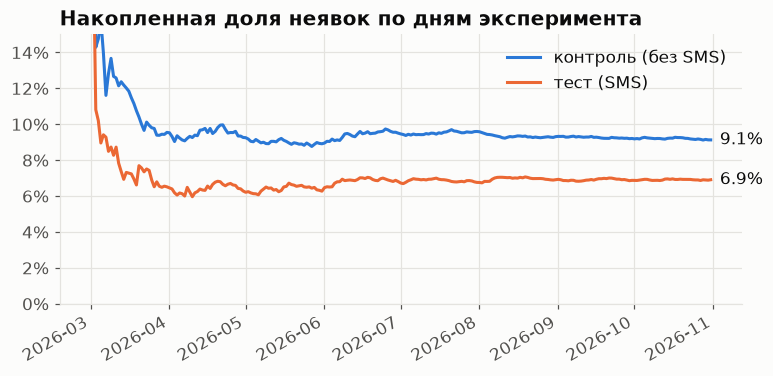

Эффект значим в обеих половинах, а интервалы пересекаются — статистически значимого угасания нет, хотя за ним стоит следить после запуска.

,контроль,тест,эффект,95% ДИ
период,,,,
первая половина,9.50%,6.81%,-28.4%,[-41.0%; -13.0%]
вторая половина,8.72%,7.02%,-19.5%,[-34.5%; -1.1%]


In [8]:
daily = main.groupby(["visit_date", "ab_group"])["is_no_show"].agg(["sum", "count"]).unstack()
cum = daily.cumsum()
cum_rate = cum["sum"] / cum["count"]

fig, ax = plt.subplots(figsize=(8, 3.6))
for grp in ["control", "treatment"]:
    ax.plot(cum_rate.index, cum_rate[grp], color=COLORS[grp], label=LABELS[grp])
    ax.annotate(
        pct(cum_rate[grp].iloc[-1]),
        (cum_rate.index[-1], cum_rate[grp].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=INK,
    )
ax.yaxis.set_major_formatter(lambda x, _: f"{100 * x:.0f}%")
ax.set_ylim(0, 0.15)
ax.legend(frameon=False, loc="upper right")
ax.set_title("Накопленная доля неявок по дням эксперимента")
fig.autofmt_xdate()
fig.savefig(f"{FIG_DIR}/02_cumulative_no_show.png")
plt.show()

mid = main["visit_date"].min() + (main["visit_date"].max() - main["visit_date"].min()) / 2
halves, halves_args = [], []
for name, part in [
    ("первая половина", main[main["visit_date"] < mid]),
    ("вторая половина", main[main["visit_date"] >= mid]),
]:
    h = part.groupby("ab_group")["is_no_show"].agg(["sum", "count"])
    args = (
        int(h.loc["control", "sum"]),
        int(h.loc["control", "count"]),
        int(h.loc["treatment", "sum"]),
        int(h.loc["treatment", "count"]),
    )
    halves_args.append(args)
    r = abtest.two_proportion_ztest(*args)
    halves.append(
        {
            "период": name,
            "контроль": pct(r.p_a, 2),
            "тест": pct(r.p_b, 2),
            "эффект": pct(r.lift),
            "95% ДИ": f"[{pct(r.lift_ci[0])}; {pct(r.lift_ci[1])}]",
        }
    )
halves = pd.DataFrame(halves).set_index("период")
h1, h2 = [abtest.two_proportion_ztest(*args) for args in halves_args]
overlap = h1.lift_ci[0] <= h2.lift_ci[1] and h2.lift_ci[0] <= h1.lift_ci[1]
display(
    Markdown(
        "Эффект значим в обеих половинах, а интервалы пересекаются — "
        "статистически значимого угасания нет, хотя за ним стоит следить после запуска."
        if overlap and h1.significant and h2.significant
        else "**Эффект заметно меняется между половинами — проверить новизну и сезонность.**"
    )
)
halves

## 4. Устойчивость результата

**Кластерный бутстрап.** Рандомизировали записи, но у одного клиента их несколько, и его записи похожи между собой
(кто-то вообще пунктуальнее). Наблюдения не независимы, и формула z-теста может занижать разброс. Бутстрап по
клиентам пересэмплирует клиентов целиком, со всеми их записями, — так зависимость учитывается.

In [9]:
boot = abtest.cluster_bootstrap_diff(main, "owner_id", "ab_group", "is_no_show", n_boot=4000, seed=42)
se_formula = (res.diff_ci[1] - res.diff_ci[0]) / (2 * 1.96)
display(
    Markdown(
        f"| Метод | Эффект | 95% ДИ | Стандартная ошибка |\n| --- | ---: | --- | ---: |\n"
        f"| Z-тест (записи независимы) | {pp(res.diff)} | [{pp(res.diff_ci[0])}; {pp(res.diff_ci[1])}] "
        f"| {100 * se_formula:.3f} п.п. |\n"
        f"| Бутстрап по клиентам | {pp(boot['diff'])} | [{pp(boot['ci'][0])}; {pp(boot['ci'][1])}] "
        f"| {100 * boot['se']:.3f} п.п. |\n\n"
        f"Ошибка с учётом клиентов больше в {boot['se'] / se_formula:.2f} раза — "
        f"{'зависимость слабая, ' if boot['se'] / se_formula < 1.1 else ''}интервал по-прежнему не содержит 0."
        if boot["ci"][1] < 0
        else "**С учётом кластеров эффект незначим — вывод неустойчив.**"
    )
)

| Метод | Эффект | 95% ДИ | Стандартная ошибка |
| --- | ---: | --- | ---: |
| Z-тест (записи независимы) | -2.22 п.п. | [-3.34 п.п.; -1.10 п.п.] | 0.572 п.п. |
| Бутстрап по клиентам | -2.22 п.п. | [-3.38 п.п.; -1.04 п.п.] | 0.593 п.п. |

Ошибка с учётом клиентов больше в 1.04 раза — зависимость слабая, интервал по-прежнему не содержит 0.

**CUPED** (Controlled-experiment Using Pre-Experiment Data) — способ сузить интервал, вычтя из метрики ту часть
разброса, которую объясняет признак, известный до эксперимента. Здесь признак — **риск неявки**, оценённый
на данных *до* эксперимента по сроку записи, понедельнику и утреннему слоту. Он известен в момент записи, до того как
монетка выбрала группу, поэтому не может зависеть от SMS и не смещает эффект — только уменьшает шум.

`y_cuped = y − θ·(x − mean(x))`, θ = cov(x, y) / var(x); дисперсия падает в (1 − corr(x, y)²) раз.

In [10]:
def lead_bucket(days):
    return pd.cut(days, [0, 1, 7, 14, np.inf], labels=["1 день", "2–7 дней", "8–14 дней", "15+ дней"])


risk_keys = ["lead_bucket", "is_monday", "is_early_slot"]
for frame in (pre, main):
    frame["lead_bucket"] = lead_bucket(frame["lead_days"])

risk = pre.groupby(risk_keys, observed=True)["is_no_show"].mean().rename("pre_risk")
main = main.join(risk, on=risk_keys)
main["pre_risk"] = main["pre_risk"].fillna(pre["is_no_show"].mean())

y = main["is_no_show"].astype(float).to_numpy()
y_cuped, theta = abtest.cuped(y, main["pre_risk"].to_numpy())
is_b = main["ab_group"].eq("treatment").to_numpy()
raw_t = abtest.welch_ttest(y[~is_b], y[is_b])
cup_t = abtest.welch_ttest(y_cuped[~is_b], y_cuped[is_b])
reduction = 1 - cup_t.se**2 / raw_t.se**2
corr = np.corrcoef(main["pre_risk"], y)[0, 1]

display(
    Markdown(
        f"| | Эффект | 95% ДИ | p-value |\n| --- | ---: | --- | ---: |\n"
        f"| Без CUPED | {pp(raw_t.diff)} | [{pp(raw_t.ci[0])}; {pp(raw_t.ci[1])}] | {raw_t.p_value:.1e} |\n"
        f"| CUPED | {pp(cup_t.diff)} | [{pp(cup_t.ci[0])}; {pp(cup_t.ci[1])}] | {cup_t.p_value:.1e} |\n\n"
        f"θ = {theta:.2f}, корреляция ковариаты с исходом {corr:.2f}. Дисперсия оценки ниже на **{pct(reduction)}**.\n\n"
        + (
            "Выигрыш маленький, и это честный результат: исход бинарный (пришёл или нет), а признаки записи объясняют "
            "его слабо — дисперсия падает лишь на corr². CUPED сильно помогает с непрерывными метриками "
            "(выручка, время) и с ковариатой «та же метрика у этого пользователя до теста». "
            "Здесь у половины клиентов до эксперимента не больше двух записей — такой истории мало. "
            "Вывод не меняется: эффект тот же, интервал почти тот же."
            if reduction < 0.05
            else f"Столько же точности без CUPED дала бы выборка на {pct(1 / (1 - reduction) - 1)} больше."
        )
    )
)

| | Эффект | 95% ДИ | p-value |
| --- | ---: | --- | ---: |
| Без CUPED | -2.22 п.п. | [-3.34 п.п.; -1.10 п.п.] | 1.0e-04 |
| CUPED | -2.17 п.п. | [-3.29 п.п.; -1.06 п.п.] | 1.3e-04 |

θ = 0.78, корреляция ковариаты с исходом 0.10. Дисперсия оценки ниже на **1.0%**.

Выигрыш маленький, и это честный результат: исход бинарный (пришёл или нет), а признаки записи объясняют его слабо — дисперсия падает лишь на corr². CUPED сильно помогает с непрерывными метриками (выручка, время) и с ковариатой «та же метрика у этого пользователя до теста». Здесь у половины клиентов до эксперимента не больше двух записей — такой истории мало. Вывод не меняется: эффект тот же, интервал почти тот же.

## 5. Мощность, A/A-тесты и подглядывание

**Мощность** — вероятность заметить эффект, если он есть. **MDE** (minimum detectable effect) — самый маленький эффект,
который тест с такой выборкой заметит с вероятностью 80%. Это считают *до* запуска, чтобы понять, сколько тест должен идти.

In [11]:
p_base = res.p_a
n_group = int(g["count"].mean())
days = (end - start).days + 1
per_day = len(main) / days / 2  # неотменённых записей в день на одну группу

mde_abs = abtest.mde(p_base, n_group)
plan = pd.DataFrame(
    [
        {
            "эффект": pct(e, 0),
            "нужно на группу": abtest.sample_size(p_base, e),
            "дней теста": int(np.ceil(abtest.sample_size(p_base, e) / per_day)),
            "мощность при нашей выборке": pct(abtest.power(p_base, e, n_group)),
        }
        for e in [-0.30, -0.20, -0.15, -0.10, -0.05]
    ]
).set_index("эффект")

display(
    Markdown(
        f"Базовая доля неявок {pct(p_base, 2)}, в группе {n_group} записей ({per_day:.1f} в день). "
        f"**MDE = {pp(-mde_abs)} ({pct(-mde_abs / p_base)} относительно)**: эффект слабее этого тест, скорее всего, пропустил бы. "
        f"Найденный эффект {pct(res.lift)} больше MDE — выборки хватило."
    )
)
plan

Базовая доля неявок 9.13%, в группе 4508 записей (18.4 в день). **MDE = -1.70 п.п. (-18.6% относительно)**: эффект слабее этого тест, скорее всего, пропустил бы. Найденный эффект -24.3% больше MDE — выборки хватило.

,нужно на группу,дней теста,мощность при нашей выборке
эффект,,,
-30%,1495,82,99.8%
-20%,3548,193,88.5%
-15%,6470,352,64.8%
-10%,14918,811,33.7%
-5%,61101,3321,11.5%


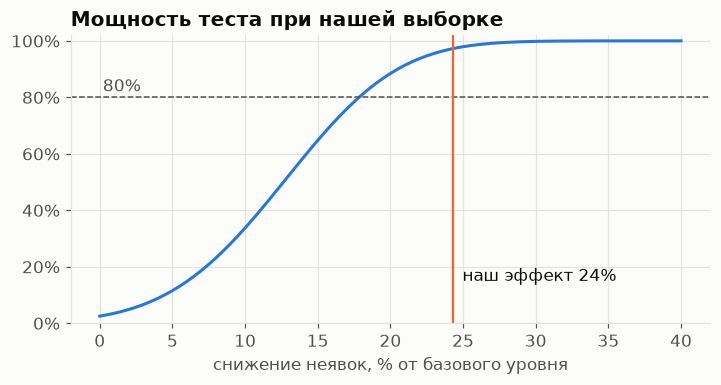

In [12]:
effects = np.linspace(0, 0.4, 81)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(100 * effects, [abtest.power(p_base, -e, n_group) for e in effects], color=COLORS["control"])
ax.axhline(0.8, color=MUTED, linewidth=1, linestyle="--")
ax.annotate("80%", (0, 0.8), xytext=(2, 4), textcoords="offset points", color=MUTED)
ax.axvline(-100 * res.lift, color=COLORS["treatment"], linewidth=1.5)
ax.annotate(
    f"наш эффект {pct(-res.lift, 0)}",
    (-100 * res.lift, 0.15),
    xytext=(6, 0),
    textcoords="offset points",
    color=INK,
)
ax.set_xlabel("снижение неявок, % от базового уровня")
ax.yaxis.set_major_formatter(lambda x, _: f"{100 * x:.0f}%")
ax.set_ylim(0, 1.02)
ax.set_title("Мощность теста при нашей выборке")
fig.savefig(f"{FIG_DIR}/03_power.png")
plt.show()

**A/A-тест** — проверка самого метода: делим данные *до* эксперимента случайно пополам много раз. Разницы точно нет,
поэтому «значимых» результатов должно быть около 5% (это и есть α — доля ложных срабатываний), а p-value должны быть
распределены равномерно. Если ложных больше — критерий на этих данных врёт.

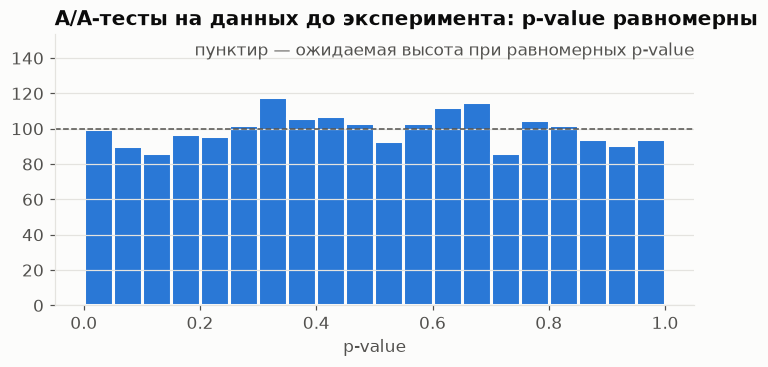

Доля ложных срабатываний в 2000 A/A-тестах: **5.0%** при номинальных 5% — z-тест работает корректно.

In [13]:
aa = abtest.aa_pvalues(pre["is_no_show"].to_numpy(), n_sims=2000, seed=1)
fpr = (aa < 0.05).mean()

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(aa, bins=20, range=(0, 1), color=COLORS["control"], edgecolor="#fcfcfb", linewidth=2)
ax.axhline(len(aa) / 20, color=MUTED, linewidth=1, linestyle="--")
counts_hist, _ = np.histogram(aa, bins=20, range=(0, 1))
ax.set_ylim(0, counts_hist.max() * 1.3)
ax.text(
    1,
    0.97,
    "пунктир — ожидаемая высота при равномерных p-value",
    transform=ax.transAxes,
    ha="right",
    va="top",
    color=MUTED,
)
ax.set_xlabel("p-value")
ax.set_title("A/A-тесты на данных до эксперимента: p-value равномерны")
ax.grid(axis="x", visible=False)
fig.savefig(f"{FIG_DIR}/04_aa_pvalues.png")
plt.show()
display(
    Markdown(
        f"Доля ложных срабатываний в 2000 A/A-тестах: **{pct(fpr)}** при номинальных 5% — z-тест работает корректно."
    )
)

**Подглядывание (peeking).** Соблазн — смотреть на p-value каждый день и остановить тест, как только стало «значимо».
Моделируем это на тех же A/A-данных, где эффекта нет: каждый день проверка, остановка при первом p < 0.05.

In [14]:
peek = abtest.peeking_false_positive_rate(
    pre["is_no_show"].to_numpy(), pre["visit_date"].to_numpy(), n_sims=1000, seed=2
)
display(
    Markdown(
        f"За {peek['looks']} ежедневных проверок: ложных срабатываний при одной проверке в конце — **{pct(peek['fpr_final'])}**, "
        f"при подглядывании — **{pct(peek['fpr_peeking'])}**, в {peek['fpr_peeking'] / peek['fpr_final']:.0f} раз больше. "
        f"Поэтому длительность теста фиксируется заранее по расчёту мощности, а промежуточные результаты не повод "
        f"останавливаться (если остановка нужна, применяют последовательные тесты с поправленными порогами)."
    )
)

За 485 ежедневных проверок: ложных срабатываний при одной проверке в конце — **4.2%**, при подглядывании — **48.1%**, в 11 раз больше. Поэтому длительность теста фиксируется заранее по расчёту мощности, а промежуточные результаты не повод останавливаться (если остановка нужна, применяют последовательные тесты с поправленными порогами).

## 6. Сегменты: где напоминание полезнее всего?

Если SMS стоят денег или их число ограничено, важно знать, где эффект больше. Проверяем несколько сегментов сразу,
поэтому растёт шанс случайно найти «значимый» — применяем **поправку Холма** на множественные сравнения.
Сегменты выбраны заранее по тому, от чего зависят неявки: срок записи, понедельник, утренний слот.

In [15]:
segments = []
specs = [
    ("срок записи", "lead_bucket", None),
    ("день", "is_monday", {True: "понедельник", False: "другие дни"}),
    ("слот", "is_early_slot", {True: "утро (до 11:00)", False: "день и вечер"}),
]
for dim, col, names in specs:
    for value, part in main.groupby(col, observed=True):
        s = part.groupby("ab_group")["is_no_show"].agg(["sum", "count"])
        r = abtest.two_proportion_ztest(
            int(s.loc["control", "sum"]),
            int(s.loc["control", "count"]),
            int(s.loc["treatment", "sum"]),
            int(s.loc["treatment", "count"]),
        )
        segments.append(
            {
                "разрез": dim,
                "сегмент": names[value] if names else str(value),
                "записей": int(s["count"].sum()),
                "контроль": r.p_a,
                "тест": r.p_b,
                "эффект, п.п.": r.diff,
                "low": r.diff_ci[0],
                "high": r.diff_ci[1],
                "эффект, %": r.lift,
                "p-value": r.p_value,
            }
        )
seg = pd.DataFrame(segments)
seg["p (Холм)"] = abtest.holm_adjust(seg["p-value"])

view = (
    seg.assign(
        **{
            "контроль": seg["контроль"].map(lambda x: pct(x, 1)),
            "тест": seg["тест"].map(lambda x: pct(x, 1)),
            "эффект, п.п.": seg["эффект, п.п."].map(pp),
            "эффект, %": seg["эффект, %"].map(pct),
            "p-value": seg["p-value"].map(lambda x: f"{x:.3f}"),
            "p (Холм)": seg["p (Холм)"].map(lambda x: f"{x:.3f}"),
        }
    )
    .drop(columns=["low", "high"])
    .set_index(["разрез", "сегмент"])
)
view

записей контроль   тест эффект, п.п. эффект, %  \
разрез      сегмент                                                           
срок записи 1 день              1653     7.9%   3.9%   -3.99 п.п.    -50.7%   
            2–7 дней            5170     8.0%   6.7%   -1.33 п.п.    -16.5%   
            8–14 дней           1640    11.3%   9.3%   -2.01 п.п.    -17.8%   
            15+ дней             553    17.1%  10.6%   -6.43 п.п.    -37.7%   
день        другие дни          7612     8.4%   6.3%   -2.13 п.п.    -25.4%   
            понедельник         1404    12.9%  10.6%   -2.29 п.п.    -17.7%   
слот        день и вечер        7812     8.8%   6.3%   -2.45 п.п.    -28.0%   
            утро (до 11:00)     1204    11.6%  10.9%   -0.72 п.п.     -6.2%   

                            p-value p (Холм)  
разрез      сегмент                           
срок записи 1 день            0.001    0.003  
            2–7 дней          0.068    0.271  
            8–14 дней         0.181    0.543  
            15+ дней          0.028    0.139  
день        другие дни        0.000    0.002  
            понедельник       0.183    0.543  
слот        день и вечер      0.000    0.000  
            утро (до 11:00)   0.691    0.691

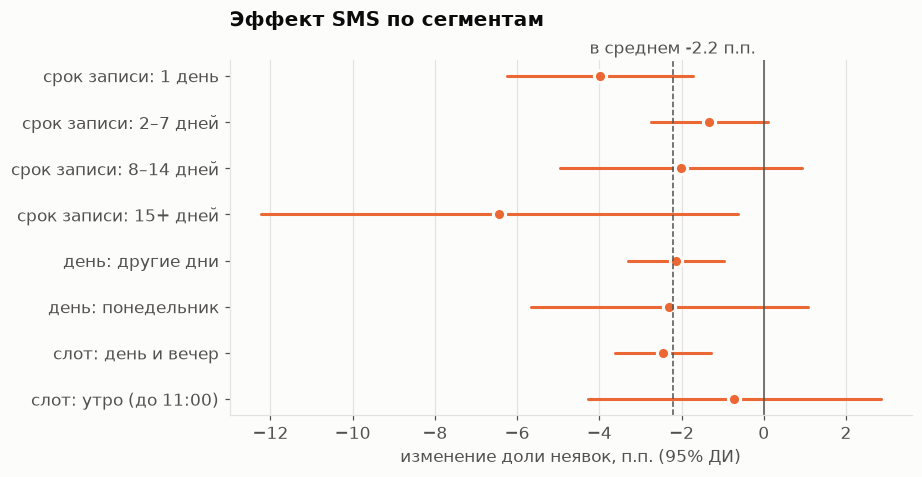

После поправки Холма эффект значим в сегментах: 1 день, другие дни, день и вечер. Оценки по сегментам сильно шумят — от -6% до -51% — и их интервалы пересекаются друг с другом и со средним эффектом. **Поэтому разница эффекта между сегментами не доказана**, и выбирать, кому слать SMS, по этой таблице нельзя: «в утреннем слоте эффекта нет» — это мало данных, а не отсутствие эффекта. Это типичная ошибка — смотреть на сегменты, пока какой-нибудь не окажется «значимым». Сегменты дают гипотезы для следующих тестов, а решение принимается по общему эффекту.

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(seg))[::-1]
for y, (_, row) in zip(ypos, seg.iterrows(), strict=True):
    ax.plot([100 * row["low"], 100 * row["high"]], [y, y], color=COLORS["treatment"], solid_capstyle="round")
    ax.plot(
        100 * row["эффект, п.п."],
        y,
        "o",
        color=COLORS["treatment"],
        markersize=8,
        markeredgecolor="#fcfcfb",
        markeredgewidth=2,
    )
ax.axvline(0, color=MUTED, linewidth=1)
ax.axvline(100 * res.diff, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(
    f"в среднем {pp(res.diff, 1)}",
    (100 * res.diff, 1),
    xycoords=("data", "axes fraction"),
    xytext=(0, 4),
    textcoords="offset points",
    ha="center",
    color=MUTED,
)
ax.set_yticks(ypos, [f"{r['разрез']}: {r['сегмент']}" for _, r in seg.iterrows()])
ax.set_xlabel("изменение доли неявок, п.п. (95% ДИ)")
ax.grid(axis="y", visible=False)
ax.set_title("Эффект SMS по сегментам", pad=22)
fig.savefig(f"{FIG_DIR}/05_segments.png")
plt.show()

significant = seg.loc[seg["p (Холм)"] < 0.05, "сегмент"].tolist()
display(
    Markdown(
        f"После поправки Холма эффект значим в сегментах: {', '.join(significant) or 'ни в одном'}. "
        f"Оценки по сегментам сильно шумят — от {pct(seg['эффект, %'].max(), 0)} до {pct(seg['эффект, %'].min(), 0)} — "
        f"и их интервалы пересекаются друг с другом и со средним эффектом. "
        f"**Поэтому разница эффекта между сегментами не доказана**, и выбирать, кому слать SMS, по этой таблице нельзя: "
        f"«в утреннем слоте эффекта нет» — это мало данных, а не отсутствие эффекта. "
        f"Это типичная ошибка — смотреть на сегменты, пока какой-нибудь не окажется «значимым». "
        f"Сегменты дают гипотезы для следующих тестов, а решение принимается по общему эффекту."
    )
)

## 7. Барьерные метрики

Напоминание не должно ломать другое. Ожидаемый риск — люди, вспомнив о приёме, чаще **отменяют** его. Отмена лучше
неявки (слот можно отдать), но если отмен становится заметно больше, чистый эффект для клиники меньше. Вторая метрика —
**выручка на запись** (считается по всем записям, включая отмены), итог для бизнеса.

In [17]:
c = exp.groupby("ab_group")["is_cancelled"].agg(["sum", "count"])
cancel = abtest.two_proportion_ztest(
    int(c.loc["control", "sum"]),
    int(c.loc["control", "count"]),
    int(c.loc["treatment", "sum"]),
    int(c.loc["treatment", "count"]),
)
is_b_exp = exp["ab_group"].eq("treatment").to_numpy()
rev = abtest.welch_ttest(exp["revenue"].to_numpy()[~is_b_exp], exp["revenue"].to_numpy()[is_b_exp])
rev_base = exp.loc[~is_b_exp, "revenue"].mean()

display(
    Markdown(
        f"| Метрика | Контроль | Тест | Изменение [95% ДИ] | p-value |\n| --- | ---: | ---: | --- | ---: |\n"
        f"| Доля отмен | {pct(cancel.p_a, 2)} | {pct(cancel.p_b, 2)} | {pp(cancel.diff)} "
        f"[{pp(cancel.diff_ci[0])}; {pp(cancel.diff_ci[1])}] | {cancel.p_value:.3f} |\n"
        f"| Выручка на запись, ₽ | {num(rev_base)} | {num(rev_base + rev.diff)} | {rev.diff:+.0f} "
        f"[{rev.ci[0]:+.0f}; {rev.ci[1]:+.0f}] | {rev.p_value:.3f} |\n\n"
        + (
            "Отмены не выросли: доля даже ниже, но разница незначима. "
            if cancel.diff_ci[1] < 0.01 and not (cancel.significant and cancel.diff > 0)
            else "**Отмены выросли — учесть в бизнес-эффекте.** "
        )
        + "Выручка на запись статистически не отличается: её разброс огромен (осмотр 1,2 тыс. ₽, "
        "операция 12+ тыс. ₽), и эффект в ~2 пункта неявок в ней тонет. Поэтому деньги оцениваем не прямым сравнением "
        "выручки, а через число сохранённых приёмов — следующий раздел."
    )
)

| Метрика | Контроль | Тест | Изменение [95% ДИ] | p-value |
| --- | ---: | ---: | --- | ---: |
| Доля отмен | 7.18% | 6.29% | -0.90 п.п. [-1.90 п.п.; +0.10 п.п.] | 0.078 |
| Выручка на запись, ₽ | 2 371 | 2 406 | +36 [-82; +153] | 0.553 |

Отмены не выросли: доля даже ниже, но разница незначима. Выручка на запись статистически не отличается: её разброс огромен (осмотр 1,2 тыс. ₽, операция 12+ тыс. ₽), и эффект в ~2 пункта неявок в ней тонет. Поэтому деньги оцениваем не прямым сравнением выручки, а через число сохранённых приёмов — следующий раздел.

## 8. Бизнес-эффект и решение

Переводим пункты в рубли, если отправлять SMS **всем** записям хотя бы за день. Допущения указаны явно —
их стоит обсуждать с бизнесом:

- **Цена SMS — 5 ₽** (типичная цена массовой рассылки; уточнить у провайдера).
- **Сохранённая неявка = средний чек приёма.** Это оценка сверху: часть пустых слотов администратор успевает
  отдать другим клиентам. Поэтому показан и осторожный вариант — половина сохранённых приёмов была бы чужой выручкой.

In [18]:
SMS_PRICE = 5.0
months = days / 30.4
bookings_per_month = len(exp) / months  # SMS уходят на все записи, включая потом отменённые
not_cancelled_per_month = len(main) / months
avg_check = main.loc[main["is_completed"], "revenue"].mean()

saved = [-not_cancelled_per_month * d for d in (res.diff, res.diff_ci[1], res.diff_ci[0])]  # точка, низ, верх
sms_cost = bookings_per_month * SMS_PRICE
rows = []
for name, share in [("оценка сверху", 1.0), ("осторожная (50% слотов не заняли бы)", 0.5)]:
    gain = [s * avg_check * share for s in saved]
    rows.append(
        {
            "сценарий": name,
            "сохранено приёмов в месяц": f"{saved[0]:.0f} [{saved[1]:.0f}; {saved[2]:.0f}]",
            "доп. выручка в месяц, ₽": f"{num(gain[0])} [{num(gain[1])}; {num(gain[2])}]",
            "SMS в месяц, ₽": num(sms_cost),
            "окупаемость": f"{gain[0] / sms_cost:.0f}×",
        }
    )
impact = pd.DataFrame(rows).set_index("сценарий")
display(
    Markdown(
        f"Записей хотя бы за день: {bookings_per_month:.0f} в месяц, средний чек {num(avg_check)} ₽. "
        f"Окупаемость — во сколько раз дополнительная выручка больше расходов на SMS."
    )
)
impact

Записей хотя бы за день: 1199 в месяц, средний чек 2 784 ₽. Окупаемость — во сколько раз дополнительная выручка больше расходов на SMS.

,сохранено приёмов в месяц,"доп. выручка в месяц, ₽","SMS в месяц, ₽",окупаемость
сценарий,,,,
оценка сверху,25 [12; 37],69 154 [34 246; 104 061],5 997,12×
осторожная (50% слотов не заняли бы),25 [12; 37],34 577 [17 123; 52 031],5 997,6×


In [19]:
display(
    Markdown(f"""
### Вывод

**SMS-напоминания снижают неявки на {pct(-res.lift, 0)}** (с {pct(res.p_a, 1)} до {pct(res.p_b, 1)};
95% ДИ относительного эффекта [{pct(res.lift_ci[0], 0)}; {pct(res.lift_ci[1], 0)}], p = {res.p_value:.0e}).
Результат устойчив: сплит корректен, группы сбалансированы, эффект держится в обеих половинах эксперимента
и с учётом зависимости записей одного клиента; отмены не выросли.

**Рекомендация: включить напоминания для всех записей хотя бы за день.** Это около {saved[0]:.0f} сохранённых
приёмов и {num(saved[0] * avg_check * 0.5)}–{num(saved[0] * avg_check)} ₽ дополнительной выручки в месяц при
расходах на SMS {num(sms_cost)} ₽: окупается даже в осторожном сценарии. Таргетировать SMS по сегментам
данные теста не позволяют — разница между сегментами не доказана.

**Ограничения.** Рандомизация по записям, а не по клиентам: клиент, получавший SMS, мог стать пунктуальнее и в
записях без SMS — тогда эффект недооценён. Данные синтетические, с заложенным эффектом −30%: он {"попадает" if res.lift_ci[0] <= -0.30 <= res.lift_ci[1] else "не попадает"}
в доверительный интервал, что заодно проверяет методику. Что дальше: тест времени отправки (за день или за 2 часа) и текста с кнопкой отмены —
чтобы неявки превращались в отмены и слот успевали отдать.
""")
)


### Вывод

**SMS-напоминания снижают неявки на 24%** (с 9.1% до 6.9%;
95% ДИ относительного эффекта [-34%; -13%], p = 1e-04).
Результат устойчив: сплит корректен, группы сбалансированы, эффект держится в обеих половинах эксперимента
и с учётом зависимости записей одного клиента; отмены не выросли.

**Рекомендация: включить напоминания для всех записей хотя бы за день.** Это около 25 сохранённых
приёмов и 34 577–69 154 ₽ дополнительной выручки в месяц при
расходах на SMS 5 997 ₽: окупается даже в осторожном сценарии. Таргетировать SMS по сегментам
данные теста не позволяют — разница между сегментами не доказана.

**Ограничения.** Рандомизация по записям, а не по клиентам: клиент, получавший SMS, мог стать пунктуальнее и в
записях без SMS — тогда эффект недооценён. Данные синтетические, с заложенным эффектом −30%: он попадает
в доверительный интервал, что заодно проверяет методику. Что дальше: тест времени отправки (за день или за 2 часа) и текста с кнопкой отмены —
чтобы неявки превращались в отмены и слот успевали отдать.
